# Experiment: Task 5 with 50 epochs
Copy of Tasks 1-5 of `Deliverable.ipynb`, with `EPOCHS = 50` and results in `Experiments/results/task5_runs_50epochs.pkl`. This notebook is not part of the submission, and any choice based on it must rely on validation scores only.

# Unfair Clause Detection

## Task 1 - Corpus
The `ToS-100` dataset is downloaded from *Zenodo* and prepared according to the assignment instructions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import urllib.request
from pathlib import Path


DOWNLOAD_DATA = False

### Download

In [2]:
ROOT = Path.cwd().parents[1]  # this notebook lives in Experiments/notebooks
data_folder = ROOT / 'Data' / 'ToS-100'
data_folder.mkdir(parents=True, exist_ok=True)

record_url = "https://zenodo.org/api/records/22691656/files"
splits = ['train', 'validation', 'test']

if DOWNLOAD_DATA:
    for split in splits:
        csv_path = data_folder / f'{split}.csv'
        urllib.request.urlretrieve(f"{record_url}/{split}.csv/content", csv_path)
        print(f"Downloaded {split} set")
dfs = {split: pd.read_csv(data_folder / f'{split}.csv') for split in splits}

### Dataset Loading and Column Drop

In [3]:
keep = ['document_ID', 'text', 'A', 'CH', 'CR', 'LTD', 'TER']

training_set = pd.read_csv(data_folder / 'train.csv')[keep]
test_set = pd.read_csv(data_folder / 'test.csv')[keep]
val_set = pd.read_csv(data_folder / 'validation.csv')[keep]


training_set

,document_ID,text,A,CH,CR,LTD,TER
0,0,websites & communications terms of use,0,0,0,0,0
1,0,please read the terms of this entire document ...,0,0,0,0,0
2,0,by accessing or signing up to receive communic...,0,0,0,0,0
3,0,our websites include multiple domains such as ...,0,0,0,0,0
4,0,you may also recognize our websites by nicknam...,0,0,0,0,0
...,...,...,...,...,...,...,...
15832,79,"you will resolve any claim , cause of action o...",0,0,0,0,0
15833,79,the laws of the state of california will gover...,0,0,0,0,0
15834,79,a party shall be excused from any delay or fai...,0,0,0,0,0
15835,79,such party shall use commercially reasonable e...,0,0,0,0,0


### Building the Target

In [4]:
label_cols = ['A', 'CH', 'CR', 'LTD', 'TER']

for df in (training_set, val_set, test_set):
    df['target'] = df[label_cols].values.tolist()

y_train = training_set[label_cols].to_numpy(dtype=np.float32)
y_val = val_set[label_cols].to_numpy(dtype=np.float32)
y_test = test_set[label_cols].to_numpy(dtype=np.float32)

training_set

,document_ID,text,A,CH,CR,LTD,TER,target
0,0,websites & communications terms of use,0,0,0,0,0,"[0, 0, 0, 0, 0]"
1,0,please read the terms of this entire document ...,0,0,0,0,0,"[0, 0, 0, 0, 0]"
2,0,by accessing or signing up to receive communic...,0,0,0,0,0,"[0, 0, 0, 0, 0]"
3,0,our websites include multiple domains such as ...,0,0,0,0,0,"[0, 0, 0, 0, 0]"
4,0,you may also recognize our websites by nicknam...,0,0,0,0,0,"[0, 0, 0, 0, 0]"
...,...,...,...,...,...,...,...,...
15832,79,"you will resolve any claim , cause of action o...",0,0,0,0,0,"[0, 0, 0, 0, 0]"
15833,79,the laws of the state of california will gover...,0,0,0,0,0,"[0, 0, 0, 0, 0]"
15834,79,a party shall be excused from any delay or fai...,0,0,0,0,0,"[0, 0, 0, 0, 0]"
15835,79,such party shall use commercially reasonable e...,0,0,0,0,0,"[0, 0, 0, 0, 0]"


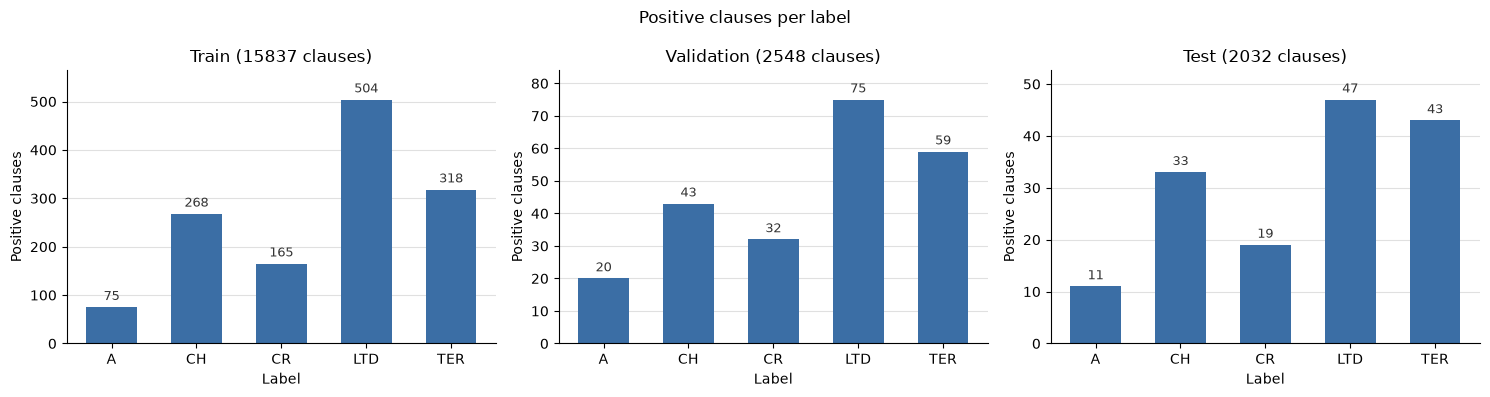

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y) in zip(axes, (('Train', y_train), ('Validation', y_val), ('Test', y_test))):
    counts = y.sum(axis=0).astype(int)
    bars = ax.bar(label_cols, counts, width=0.6, color='#3b6ea5')
    ax.bar_label(bars, padding=3, fontsize=9, color='#333333')
    ax.set_title(f"{name} ({len(y)} clauses)")
    ax.set_xlabel('Label')
    ax.set_ylabel('Positive clauses')
    ax.margins(y=0.12)
    ax.grid(axis='y', color='#e0e0e0', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Positive clauses per label')
fig.tight_layout()
plt.show()

### Report

In [6]:
stats = {}
for name, y in (('train', y_train), ('validation', y_val), ('test', y_test)):
    n_labels = y.sum(axis=1)
    stats[name] = {
        'clauses': len(y),
        'positive clauses': int((n_labels >= 1).sum()),
        **{f'pos {label}': int(count) for label, count in zip(label_cols, y.sum(axis=0))},
        '0 labels': int((n_labels == 0).sum()),
        '1 label': int((n_labels == 1).sum()),
        '2+ labels': int((n_labels >= 2).sum()),
    }

stats_df = pd.DataFrame(stats).T
stats_df

,clauses,positive clauses,pos A,pos CH,pos CR,pos LTD,pos TER,0 labels,1 label,2+ labels
train,15837,1223,75,268,165,504,318,14614,1124,99
validation,2548,212,20,43,32,75,59,2336,195,17
test,2032,139,11,33,19,47,43,1893,127,12


As anticipated by the assignment, the corpus is **heavily imbalanced**: 92.3% of the training clauses carry no label.

## Task 2a - Data Cleaning
The data has already been tokenized, so the remaining tokenizer artifacts must be restored.

In [7]:
import re

import nltk
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

ENUMERATOR = r"(?:\d+|[a-z]|[ivx]+)"
NUMBERING_RE = re.compile(
    rf"^(?:-l[rs]b- {ENUMERATOR} -r[rs]b-"
    rf"|{ENUMERATOR} -r[rs]b-"
    rf"|\d+(?:\.\d+)+\.?"
    rf"|\d+ [.°]"
    rf"|[•·●*-])\s+"
)
TOKEN_MAP = {
    '-lrb-': '(', '-rrb-': ')', '-lsb-': '[', '-rsb-': ']', '-lcb-': '{', '-rcb-': '}',
    '``': '"', "''": '"', '`': "'",
}
CLITICS = {"'s", "'re", "'ve", "'ll", "'d", "'m", "n't"}
SPECIAL_CHARS_RE = re.compile(r"[^a-z0-9\s.,;:!?()\[\]{}\"'/$%&@-]")

lemmatizer = WordNetLemmatizer()


def get_wordnet_key(tag: str) -> str | None:
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return None


def strip_numbering(text: str) -> str:
    while (stripped := NUMBERING_RE.sub('', text, count=1)) != text:
        text = stripped
    return text


def lemmatize(tokens: list[str]) -> list[str]:
    lemmas = []
    for i, (word, tag) in enumerate(pos_tag(tokens)):
        key = get_wordnet_key(tag)
        before_negation = i + 1 < len(tokens) and tokens[i + 1] == "n't"
        lemmas.append(lemmatizer.lemmatize(word, key) if key and not before_negation else word)
    return lemmas


def reattach_clitics(tokens: list[str]) -> list[str]:
    merged = []
    for token in tokens:
        if token in CLITICS and merged:
            merged[-1] += token
        else:
            merged.append(token)
    return merged


def clean_text(text: str) -> str:
    text = strip_numbering(text)
    tokens = [TOKEN_MAP.get(token, token) for token in text.split()]
    tokens = reattach_clitics(lemmatize(tokens))
    text = SPECIAL_CHARS_RE.sub(' ', ' '.join(tokens))
    return ' '.join(text.split())


for df in (training_set, val_set, test_set):
    df['clean_text'] = df['text'].apply(clean_text)

In [8]:
examples = training_set['text'].str.match(r"^(?:-lrb- \w+ -rrb-|\d+\.\d+|[•·●*-] )|.*(?:n't|``)")
pd.set_option('display.max_colwidth', None)
training_set.loc[examples, ['text', 'clean_text']].sample(8, random_state=0)

,text,clean_text
14879,"our logo and the terms `` couchsurfing '' and `` couchsurfer '' , as well as other terms and visual elements that you might see throughout the couchsurfing services , are protected trademarks .","our logo and the term "" couchsurfing "" and "" couchsurfer "" , as well as other term and visual element that you might see throughout the couchsurfing service , be protect trademark ."
4772,2.1 we aim to deliver the product to you at the place of delivery requested by you in your order .,we aim to deliver the product to you at the place of delivery request by you in your order .
15564,you must choose an account name for your account which may also serve as the name for your graphical representation within each product -lrb- your `` avatar '' -rrb- .,"you must choose an account name for your account which may also serve as the name for your graphical representation within each product ( your "" avatar "" ) ."
2717,22.9 if you have any questions about these terms please email us .,if you have any question about these term please email us .
9640,"if you purchase or subscribe to such paid services , you agree to pay us the applicable fees -lrb- `` truecaller fees '' -rrb- and taxes in accordance with the applicable third party payment and billing terms , based on the platform you are using , which are incorporated herein by reference .","if you purchase or subscribe to such pay service , you agree to pay us the applicable fee ( "" truecaller fee "" ) and tax in accordance with the applicable third party payment and billing term , base on the platform you be use , which be incorporate herein by reference ."
10263,the service is provided by paradox on an `` as is '' and `` as available '' basis .,"the service be provide by paradox on an "" as be "" and "" as available "" basis ."
8300,"article r.211-5 : `` the information mentioned in sections 1 ° , 3 ° , 4 ° , 5 ° and 7 ° of article r. 2114 communicated to the traveller forms part of the contract and can only be modified under the conditions defined in article l. 211 - 9 . ''","article r.211-5 : "" the information mention in section 1 , 3 , 4 , 5 and 7 of article r. 2114 communicate to the traveller form part of the contract and can only be modify under the condition define in article l. 211 - 9 . """
4563,"4.8 your order remains valid as an offer until we issue our confirmation of order or , if earlier , when we receive your notice revoking your order .","your order remain valid as an offer until we issue our confirmation of order or , if early , when we receive your notice revoke your order ."


## Task 2b - Label Analysis
The training set is examined to choose the imbalance strategy used in Task 5.

### Positive Rate per Category

In [9]:
pos_rate = pd.Series(y_train.mean(axis=0), index=label_cols, name='positive rate')
(pos_rate * 100).round(2).to_frame('positive rate (%)')

,positive rate (%)
A,0.47
CH,1.69
CR,1.04
LTD,3.18
TER,2.01


### Co-occurrence

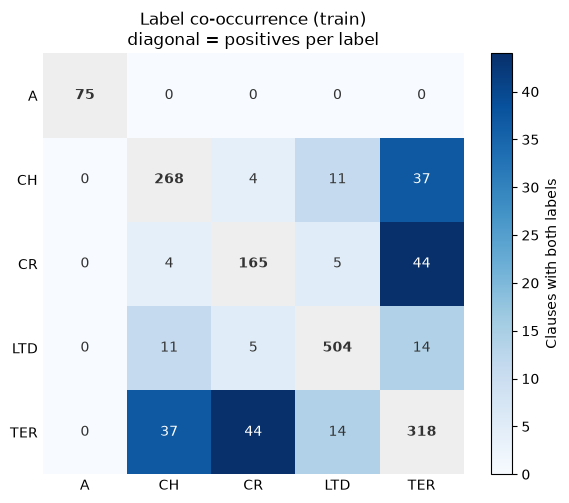

In [10]:
cooc = pd.DataFrame((y_train.T @ y_train).astype(int), index=label_cols, columns=label_cols)

off_diag = np.ma.masked_where(np.eye(len(label_cols), dtype=bool), cooc.to_numpy())
cmap = plt.get_cmap('Blues').copy()
cmap.set_bad('#eeeeee')

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(off_diag, cmap=cmap, vmin=0)

for i in range(len(label_cols)):
    for j in range(len(label_cols)):
        value = cooc.iat[i, j]
        dark_cell = i != j and value > off_diag.max() / 2
        ax.text(j, i, value, ha='center', va='center', fontsize=10,
                color='white' if dark_cell else '#333333', fontweight='bold' if i == j else 'normal')

ax.set_xticks(range(len(label_cols)), label_cols)
ax.set_yticks(range(len(label_cols)), label_cols)
ax.set_title('Label co-occurrence (train)\ndiagonal = positives per label')
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, label='Clauses with both labels')
fig.tight_layout()
plt.show()

The heatmap above highlights a strong imbalance across labels: `A` occurs only 75 times in the training set, less than half as often as `CR`, the second rarest. Moreover, `A` never co-occurs with any other label, so oversampling `A` clauses alone does not inflate the counts of other categories. Each `A` clause is therefore repeated 4 times in the training set only.

Positive rates are, however, low for every category. Therefore, in Task 5 the loss is also **reweighted** through the `pos_weight` argument of `BCEWithLogitsLoss`, with a separate weight for the positive class of each category, computed on the oversampled training set:
$$
    L_c = - [w_c y_c \log \hat{y}_c + (1-y_c) \log(1- \hat{y}_c)], \quad w_c = \frac{N_c^{neg}}{N_c^{pos}}
$$

Four observations motivate this choice:
- **An unweighted loss would be dominated by negatives**: predicting "no label" already reaches an accuracy of about 92% and a low binary cross-entropy. Weighting makes positive and negative samples contribute equally to the loss.
- **It matches the multi-label formulation**: each category is an independent binary decision with its own degree of imbalance.
- **It aligns training with the evaluation metric**: macro F1 weighs all five categories equally, so the rare ones cannot be sacrificed in favour of the frequent ones.
- **It covers every category**: oversampling treats only `A`, whereas reweighting acts on all five.

## Task 3 - Text Encoding
The cleaned text is encoded with `GloVe` embeddings. The vocabulary covers every training token, while validation and test OOV tokens are mapped to `<UNK>`. The OOV rate is reported for each split, since legal text contains domain-specific words that a general-purpose embedding model may not cover.

### Embedding
Dense embeddings need fewer parameters than sparse representations, which reduces the risk of overfitting, and generalise better to related words. The 100-dimensional `glove-wiki-gigaword` is used: since the Embedding layer is trainable, it holds |V| × d ≈ 40M parameters (120M with d = 300) for about 16k training clauses.

In [11]:
from collections import Counter

import gensim.downloader as gloader

glove = gloader.load('glove-wiki-gigaword-100')

PAD, UNK = '<PAD>', '<UNK>'
PAD_IDX, UNK_IDX = 0, 1

train_counts = Counter(token for text in training_set['clean_text'] for token in text.split())
train_oov = [token for token in train_counts if token not in glove.key_to_index]

idx_to_word = [PAD, UNK] + glove.index_to_key + train_oov
word_to_idx = {word: idx for idx, word in enumerate(idx_to_word)}

print(f"GloVe words: {len(glove.index_to_key)}, train tokens added: {len(train_oov)}, vocabulary size: {len(word_to_idx)}")

GloVe words: 400000, train tokens added: 1520, vocabulary size: 401522


### OOV Handling
- **GloVe words**: pre-trained GloVe vector.
- **Training tokens missing from GloVe**: mean of the GloVe vectors of their parts, obtained by detaching a trailing clitic (`don't` → `do` + `n't`) and splitting on `-` and `/` (`non-infringement` → `non` + `infringement`). Most of these tokens come from the clitic reattachment of Task 2a or are compounds of known words. Tokens with no part in GloVe (mostly brand names) get a random vector from U(-0.05, 0.05).
- **`<UNK>`**: fixed random vector from U(-0.05, 0.05), for validation and test tokens outside the vocabulary.
- **`<PAD>`**: zero vector.

In [12]:
def compose_vector(token: str) -> np.ndarray | None:
    clitic = next((c for c in CLITICS if token.endswith(c) and token != c), None)
    stem = token[:-len(clitic)] if clitic else token
    parts = re.split(r'[-/]', stem) + ([clitic] if clitic else [])
    vectors = [glove[part] for part in parts if part in glove.key_to_index]
    return np.mean(vectors, axis=0) if vectors else None


rng = np.random.default_rng(42)
embedding_dim = glove.vector_size

embedding_matrix = np.zeros((len(idx_to_word), embedding_dim), dtype=np.float32)
embedding_matrix[UNK_IDX] = rng.uniform(-0.05, 0.05, embedding_dim)
embedding_matrix[2:2 + len(glove.index_to_key)] = glove.vectors

composed = []
for token in train_oov:
    vector = compose_vector(token)
    if vector is None:
        vector = rng.uniform(-0.05, 0.05, embedding_dim)
    else:
        composed.append(token)
    embedding_matrix[word_to_idx[token]] = vector

print(f"Embedding matrix shape: {embedding_matrix.shape}")
print(f"Train OOV tokens: {len(train_oov)} -> composed from GloVe parts: {len(composed)}, random: {len(train_oov) - len(composed)}")

Embedding matrix shape: (401522, 100)
Train OOV tokens: 1520 -> composed from GloVe parts: 794, random: 726


In [13]:
print("Composition check: 5 closest GloVe words for each composed token\n")
for token in ["don't", "member's", "non-infringement", "you're"]:
    neighbours = glove.similar_by_vector(embedding_matrix[word_to_idx[token]], topn=5)
    print(f"{token:>18} -> {[word for word, _ in neighbours]}")

Composition check: 5 closest GloVe words for each composed token

             don't -> ['do', "n't", 'know', 'you', 'want']
          member's -> ["'s", 'member', 'the', 'one', 'whose']
  non-infringement -> ['infringement', 'non', 'violation', 'rights', 'copyright']
            you're -> ['you', "'re", "'ll", "n't", 'know']


Although the Embedding layer is trainable, `<UNK>` stays static: every training token is in the vocabulary and no training clause is empty after cleaning, so `<UNK>` never occurs in a training batch and receives no gradient.

In [14]:
def encode(text: str) -> list[int]:
    return [word_to_idx.get(token, UNK_IDX) for token in text.split()]


for df in (training_set, val_set, test_set):
    df['token_ids'] = df['clean_text'].apply(encode)

In [15]:
oov_report = {}
for name, df in (('train', training_set), ('validation', val_set), ('test', test_set)):
    counts = Counter(token for text in df['clean_text'] for token in text.split())
    if name == 'train':
        oov = [token for token in counts if token not in glove.key_to_index]
    else:
        oov = [token for token in counts if token not in word_to_idx]
    oov_report[name] = {
        'token types': len(counts),
        'OOV types': len(oov),
        'OOV types (%)': round(100 * len(oov) / len(counts), 2),
        'OOV occurrences (%)': round(100 * sum(counts[token] for token in oov) / counts.total(), 2),
    }

pd.DataFrame.from_dict(oov_report, orient='index')

,token types,OOV types,OOV types (%),OOV occurrences (%)
train,8228,1520,18.47,1.11
validation,3501,200,5.71,0.58
test,3346,156,4.66,0.81


The final vocabulary has 401,522 entries: `<PAD>`, `<UNK>`, the 400,000 GloVe words and 1,520 training tokens missing from GloVe.

Almost one training type in five is missing from GloVe, but these types cover only 1.1% of the occurrences; they are mostly brand names, reattached clitics and hyphenated compounds. The legal vocabulary, on the other hand, is largely covered. `<UNK>` tokens are below 1% of the occurrences in both validation and test, so their impact should be limited.

### Padding and Truncation
- **Dynamic padding**: each batch is padded with `<PAD>` (index 0) to its longest clause.
- **Truncation**: each clause keeps its first `MAX_LEN` tokens; `MAX_LEN` is chosen on the training set.
- **`padding_idx=0`**: the `<PAD>` vector stays zero and receives no gradient (equivalent to `mask_zero=True`).
- **Packing**: `pack_padded_sequence` makes the Bi-LSTM skip `<PAD>`, so the hidden states depend only on the real tokens.

In [16]:
train_lengths = training_set['token_ids'].str.len()
positive = y_train.any(axis=1)

length_report = {}
for name, lengths in (('all clauses', train_lengths), ('positive clauses', train_lengths[positive])):
    length_report[name] = {
        'mean': round(lengths.mean(), 1),
        'median': lengths.median(),
        'p95': lengths.quantile(0.95),
        'p99': lengths.quantile(0.99),
        'max': lengths.max(),
        **{f'> {n} tokens': int((lengths > n).sum()) for n in (64, 100, 128, 150)},
    }

pd.DataFrame.from_dict(length_report, orient='index')

,mean,median,p95,p99,max,> 64 tokens,> 100 tokens,> 128 tokens,> 150 tokens
all clauses,32.0,26.0,75.0,131.64,353,1221,335,169,97
positive clauses,44.0,33.0,109.8,200.00,353,204,75,43,30


Positive clauses are longer than average, so a short `MAX_LEN` would mostly cut the clauses to detect. `MAX_LEN = 150` (about the 99th percentile) truncates 97 training clauses (30 positive) and avoids very long sequences.

In [17]:
import torch
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset

MAX_LEN = 150


class ClauseDataset(Dataset):
    def __init__(self, token_ids: pd.Series, labels: np.ndarray):
        self.sequences = [torch.tensor((ids or [UNK_IDX])[:MAX_LEN]) for ids in token_ids]
        self.labels = torch.tensor(labels)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]


def collate(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences])
    padded = pad_sequence(sequences, batch_first=True, padding_value=PAD_IDX)
    return padded, lengths, torch.stack(labels)


truncated = int((train_lengths > MAX_LEN).sum())
print(f"MAX_LEN = {MAX_LEN}: truncated train clauses {truncated} ({100 * truncated / len(train_lengths):.2f}%), "
      f"of which positive {int((train_lengths[positive] > MAX_LEN).sum())}")

padded, lengths, labels = collate([ClauseDataset(val_set['token_ids'], y_val)[i] for i in range(4)])
print(f"example batch: ids {tuple(padded.shape)}, lengths {lengths.tolist()}, targets {tuple(labels.shape)}")

MAX_LEN = 150: truncated train clauses 97 (0.61%), of which positive 30
example batch: ids (4, 91), lengths [91, 10, 27, 25], targets (4, 5)


## Task 4 - Model Definition

### Architecture
Two recurrent classifiers are defined, which differ only in depth: the **Baseline** is a Bidirectional LSTM with a Dense layer on top, and the **Stacked** model adds a second Bidirectional LSTM layer. Since a clause can be unfair under several categories at once, the solution does not adopt softmax, but rather outputs one independent score per category instead of a single choice among five classes.

Both models read the token ids of Task 3 through an Embedding layer initialized with the embedding matrix. Each clause is represented by the element-wise maximum of the hidden states of the last Bi-LSTM layer over all its tokens, which do not include `<PAD>`.

This encoding was compared with the concatenation of the final forward and backward states on the Baseline (`Experiments/embedding_frozen.py`): the maximum reaches a validation macro F1 of 0.546 ± 0.006 against 0.507 ± 0.015, and is better on all three seeds and all five categories. It adds no parameters, so the layers of the model do not change. The Stacked model uses the same encoding, without a separate comparison.

In [18]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence


class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix: np.ndarray, hidden_size: int, num_layers: int, n_labels: int = len(label_cols),
                 freeze_embedding: bool = False):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix), freeze=freeze_embedding, padding_idx=PAD_IDX
        )
        self.lstm = nn.LSTM(embedding_matrix.shape[1], hidden_size, num_layers=num_layers,
                            batch_first=True, bidirectional=True)
        self.dense = nn.Linear(2 * hidden_size, n_labels)

    def forward(self, token_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        packed = pack_padded_sequence(self.embedding(token_ids), lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        outputs, _ = self.lstm(packed)
        states, _ = pad_packed_sequence(outputs, batch_first=True)
        padding = torch.arange(states.size(1), device=states.device) >= lengths.to(states.device).unsqueeze(1)
        return self.dense(states.masked_fill(padding.unsqueeze(-1), float('-inf')).max(dim=1).values)

### Baseline and Stacked
Both models use 128 hidden units per direction, so that the Dense layer receives a 256-dimensional vector. In the Stacked model, the second Bi-LSTM layer reads the concatenated outputs of the first one; every other component is the same.

In [19]:
HIDDEN_SIZE = 128
MODEL_LAYERS = {'Baseline': 1, 'Stacked': 2}

for name, num_layers in MODEL_LAYERS.items(): 
    model = BiLSTMClassifier(embedding_matrix, HIDDEN_SIZE, num_layers)
    with torch.no_grad():
        logits = model(padded, lengths)
    embedding_params = model.embedding.weight.numel()
    other_params = sum(p.numel() for p in model.parameters()) - embedding_params
    print(f"{name}: output {tuple(logits.shape)}, parameters excluding Embedding {other_params:,}, Embedding {embedding_params:,}")

Baseline: output (4, 5), parameters excluding Embedding 236,805, Embedding 40,152,200
Stacked: output (4, 5), parameters excluding Embedding 632,069, Embedding 40,152,200


## Task 5 - Training and Evaluation
Baseline and Stacked are trained with the imbalance strategy of Task 2b and evaluated on the validation and test sets. Every choice (best epoch, decision thresholds, best model) relies on the validation set only: test scores are just reported.

### Configuration
Each model is trained with 3 seeds for 50 epochs, on mini-batches of 64 clauses. The optimizer is Adam, which adapts the step of each parameter: `pos_weight` gives the categories very different gradient scales, so a single fixed step would need a costly search of the learning rate.

In [20]:
import time

SEEDS = [42, 1337, 2026]
EPOCHS = 50
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def set_seed(seed: int):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


print(f"Device: {DEVICE}")

Device: cuda

### Imbalance Strategy
`A` clauses are repeated `A_FACTOR = 4` times in the training set only, after the vocabulary has been built. `pos_weight` is then computed on the oversampled set, so the weight of `A` drops from about 210 to about 52.

The two options were compared on the Baseline with a trainable Embedding layer (`Experiments/embedding_frozen.py`): `A_FACTOR = 4` reaches a validation macro F1 of 0.507 ± 0.015 against 0.489 ± 0.023 without oversampling. The gap is within the variability across seeds, so it supports the choice without proving it.

In [21]:
from torch.utils.data import DataLoader

A_FACTOR = 4

a_clauses = training_set[training_set['A'] == 1]
train_resampled = pd.concat([training_set] + [a_clauses] * (A_FACTOR - 1), ignore_index=True)
y_resampled = train_resampled[label_cols].to_numpy(dtype=np.float32)

n_pos = y_resampled.sum(axis=0)
pos_weight = torch.tensor((len(y_resampled) - n_pos) / n_pos)

train_dataset = ClauseDataset(train_resampled['token_ids'], y_resampled)
val_loader = DataLoader(ClauseDataset(val_set['token_ids'], y_val), batch_size=256, collate_fn=collate)
test_loader = DataLoader(ClauseDataset(test_set['token_ids'], y_test), batch_size=256, collate_fn=collate)

print(f"Training clauses: {len(training_set)} -> {len(train_resampled)}")
print(f"pos_weight: { {label: round(weight, 1) for label, weight in zip(label_cols, pos_weight.tolist())} }")

Training clauses: 15837 -> 16062
pos_weight: {'A': 52.5, 'CH': 58.9, 'CR': 96.3, 'LTD': 30.9, 'TER': 49.5}


### Metrics and Threshold Tuning
Macro precision, recall and F1 average the five binary scores computed on the positive class. Per-category F1 is also reported, since the macro average hides the differences between categories.

For each category, the threshold is the value in {0.05, 0.10, ..., 0.95} that maximises F1 on the validation set. Validation scores with tuned thresholds are therefore optimistic, while test scores are not. With only 20 positive `A` clauses in validation the choice is noisy, so the thresholds are reported with their variability across seeds.

In [22]:
from sklearn.metrics import f1_score, precision_score, recall_score

THRESHOLD_GRID = np.arange(0.05, 0.96, 0.05)


def compute_metrics(y_true: np.ndarray, probs: np.ndarray, thresholds: float | np.ndarray = 0.5) -> dict:
    y_pred = (probs >= thresholds).astype(int)
    per_category = f1_score(y_true, y_pred, average=None, zero_division=0)
    return {
        'macro F1': per_category.mean(),
        'macro precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'macro recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        **{f'F1 {label}': score for label, score in zip(label_cols, per_category)},
    }


def tune_thresholds(y_true: np.ndarray, probs: np.ndarray) -> np.ndarray:
    thresholds = []
    for c in range(y_true.shape[1]):
        scores = [f1_score(y_true[:, c], probs[:, c] >= t, zero_division=0) for t in THRESHOLD_GRID]
        thresholds.append(THRESHOLD_GRID[np.argmax(scores)])
    return np.array(thresholds)

### Training Loop
After each epoch the model is evaluated on the validation set, and the weights of the epoch with the highest macro F1 (threshold 0.5) are kept. The thresholds are then tuned on those weights, and the test set is used only at this point.

In [23]:
@torch.no_grad()
def predict_proba(model: nn.Module, loader: DataLoader) -> np.ndarray:
    model.eval()
    return np.concatenate([torch.sigmoid(model(ids.to(DEVICE), lengths)).cpu().numpy() for ids, lengths, _ in loader])


def train_model(num_layers: int, seed: int) -> dict:
    set_seed(seed)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate,
                              generator=torch.Generator().manual_seed(seed))

    model = BiLSTMClassifier(embedding_matrix, HIDDEN_SIZE, num_layers).to(DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    best_f1, best_epoch, best_state = -1.0, 0, None
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        epoch_loss = 0.0
        for ids, lengths, labels in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(ids.to(DEVICE), lengths), labels.to(DEVICE))
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(labels)

        val_f1 = compute_metrics(y_val, predict_proba(model, val_loader))['macro F1']
        history.append({'epoch': epoch, 'train_loss': epoch_loss / len(train_dataset), 'val_macro_f1': val_f1})
        if val_f1 > best_f1:
            best_f1, best_epoch = val_f1, epoch
            best_state = {key: value.cpu().clone() for key, value in model.state_dict().items()}

    model.load_state_dict(best_state)
    val_probs = predict_proba(model, val_loader)
    return {
        'seed': seed,
        'best_epoch': best_epoch,
        'history': history,
        'val_probs': val_probs,
        'test_probs': predict_proba(model, test_loader),
        'thresholds': tune_thresholds(y_val, val_probs),
    }

### Baseline and Stacked Runs
Probabilities, thresholds and curves of every run are saved to a file for the following sections. With `TRAIN_MODELS = False` the runs are reloaded instead of being trained again.

In [24]:
from tqdm import tqdm

TRAIN_MODELS = True
RUNS_FILE = ROOT / 'Experiments' / 'results' / 'task5_runs_50epochs.pkl'

if TRAIN_MODELS:
    RUNS_FILE.parent.mkdir(parents=True, exist_ok=True)
    runs = {name: [] for name in MODEL_LAYERS}
    configs = [(name, num_layers, seed) for name, num_layers in MODEL_LAYERS.items() for seed in SEEDS]
    for name, num_layers, seed in tqdm(configs, desc='Runs'):
        start = time.time()
        run = train_model(num_layers, seed)
        runs[name].append(run)
        pd.to_pickle(runs, RUNS_FILE)
        tqdm.write(f"{name} | seed {seed} | best epoch {run['best_epoch']:2d} | "
                   f"val macro F1 {run['history'][run['best_epoch'] - 1]['val_macro_f1']:.4f} | {time.time() - start:.0f} s")
else:
    runs = pd.read_pickle(RUNS_FILE)

Runs:   0%|          | 0/6 [00:00<?, ?it/s]

Runs:   0%|          | 0/6 [08:59<?, ?it/s]

Runs:  17%|█▋        | 1/6 [08:59<44:56, 539.33s/it]

Baseline | seed 42 | best epoch 45 | val macro F1 0.5683 | 539 s


Runs:  17%|█▋        | 1/6 [19:00<44:56, 539.33s/it]

Runs:  33%|███▎      | 2/6 [19:00<38:21, 575.42s/it]

... (10 outputs left out)

Runs:  83%|████████▎ | 5/6 [1:17:41<13:24, 804.34s/it]

Runs: 100%|██████████| 6/6 [1:17:41<00:00, 872.11s/it]

Runs: 100%|██████████| 6/6 [1:17:41<00:00, 776.85s/it]

Stacked | seed 2026 | best epoch 22 | val macro F1 0.5285 | 1004 s


### Results

In [25]:
def mean_std(scores: pd.DataFrame) -> pd.Series:
    return scores.mean().map('{:.3f}'.format) + ' ± ' + scores.std().map('{:.3f}'.format)


results = {}
for name, model_runs in runs.items():
    for split, y_true, key in (('validation', y_val, 'val_probs'), ('test', y_test, 'test_probs')):
        at_half = [compute_metrics(y_true, run[key]) for run in model_runs]
        tuned = [compute_metrics(y_true, run[key], run['thresholds']) for run in model_runs]
        results[(name, split, '0.5')] = mean_std(pd.DataFrame(at_half))
        results[(name, split, 'tuned')] = mean_std(pd.DataFrame(tuned))

results_table = pd.DataFrame(results).T.rename_axis(['model', 'split', 'threshold'])
thresholds_table = pd.DataFrame({
    name: mean_std(pd.DataFrame([run['thresholds'] for run in model_runs], columns=label_cols))
    for name, model_runs in runs.items()
}).T.rename_axis('tuned threshold')

display(results_table)
display(thresholds_table)

macro F1 macro precision   macro recall  \
model    split      threshold                                                 
Baseline validation 0.5        0.553 ± 0.014   0.530 ± 0.069  0.598 ± 0.056   
                    tuned      0.592 ± 0.009   0.609 ± 0.007  0.589 ± 0.035   
         test       0.5        0.617 ± 0.002   0.565 ± 0.052  0.695 ± 0.072   
                    tuned      0.638 ± 0.028   0.622 ± 0.016  0.667 ± 0.046   
Stacked  validation 0.5        0.549 ± 0.018   0.516 ± 0.014  0.602 ± 0.053   
                    tuned      0.572 ± 0.014   0.570 ± 0.025  0.589 ± 0.038   
         test       0.5        0.628 ± 0.034   0.564 ± 0.053  0.723 ± 0.005   
                    tuned      0.629 ± 0.035   0.585 ± 0.052  0.695 ± 0.021   

                                        F1 A          F1 CH          F1 CR  \
model    split      threshold                                                
Baseline validation 0.5        0.435 ± 0.070  0.577 ± 0.044  0.584 ± 0.044   
                    tuned      0.480 ± 0.018  0.609 ± 0.008  0.644 ± 0.020   
         test       0.5        0.456 ± 0.043  0.731 ± 0.023  0.593 ± 0.039   
                    tuned      0.507 ± 0.047  0.746 ± 0.017  0.621 ± 0.049   
Stacked  validation 0.5        0.423 ± 0.040  0.526 ± 0.061  0.569 ± 0.036   
                    tuned      0.446 ± 0.030  0.538 ± 0.061  0.609 ± 0.019   
         test       0.5        0.541 ± 0.021  0.708 ± 0.064  0.598 ± 0.065   
                    tuned      0.543 ± 0.042  0.721 ± 0.059  0.565 ± 0.047   

                                      F1 LTD         F1 TER  
model    split      threshold                                
Baseline validation 0.5        0.608 ± 0.028  0.562 ± 0.017  
                    tuned      0.628 ± 0.031  0.598 ± 0.031  
         test       0.5        0.634 ± 0.027  0.668 ± 0.019  
                    tuned      0.648 ± 0.027  0.667 ± 0.031  
Stacked  validation 0.5        0.620 ± 0.006  0.609 ± 0.042  
                    tuned      0.651 ± 0.003  0.616 ± 0.039  
         test       0.5        0.597 ± 0.031  0.696 ± 0.043  
                    tuned      0.617 ± 0.033  0.699 ± 0.056

,A,CH,CR,LTD,TER
tuned threshold,,,,,
Baseline,0.700 ± 0.229,0.700 ± 0.218,0.700 ± 0.304,0.533 ± 0.306,0.633 ± 0.425
Stacked,0.767 ± 0.236,0.633 ± 0.029,0.517 ± 0.379,0.800 ± 0.050,0.600 ± 0.229


### Learning Curves

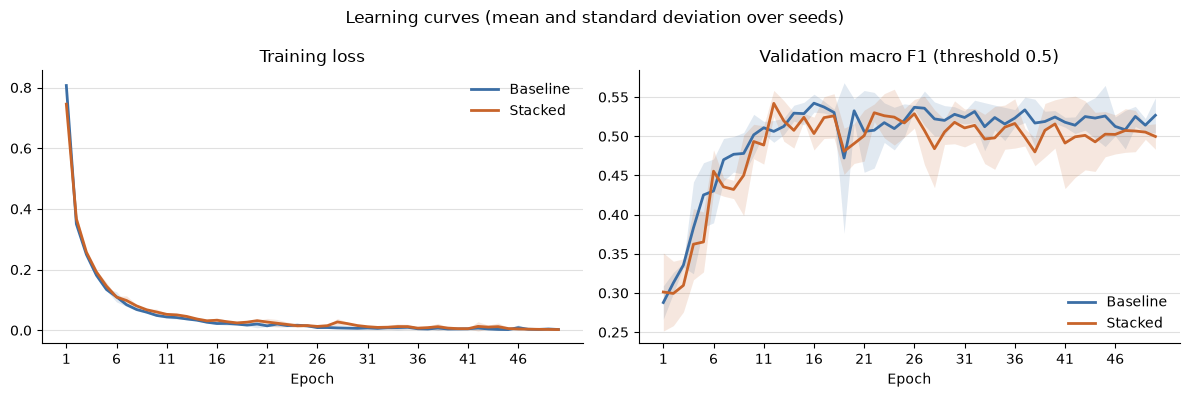

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {'Baseline': '#3b6ea5', 'Stacked': '#c8642a'}

for ax, (metric, title) in zip(axes, (('train_loss', 'Training loss'), ('val_macro_f1', 'Validation macro F1 (threshold 0.5)'))):
    for name, model_runs in runs.items():
        curves = np.array([[step[metric] for step in run['history']] for run in model_runs])
        epochs = np.arange(1, curves.shape[1] + 1)
        ax.plot(epochs, curves.mean(axis=0), color=colors[name], linewidth=2, label=name)
        ax.fill_between(epochs, curves.mean(axis=0) - curves.std(axis=0, ddof=1), curves.mean(axis=0) + curves.std(axis=0, ddof=1),
                        color=colors[name], alpha=0.15, linewidth=0)
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.set_xticks(epochs[::5])
    ax.grid(axis='y', color='#e0e0e0', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False)

fig.suptitle('Learning curves (mean and standard deviation over seeds)')
fig.tight_layout()
plt.show()

### Model Selection

In [27]:
val_macro_f1 = {
    name: np.mean([compute_metrics(y_val, run['val_probs'], run['thresholds'])['macro F1'] for run in model_runs])
    for name, model_runs in runs.items()
}
best_model = max(val_macro_f1, key=val_macro_f1.get)

print({name: round(float(score), 4) for name, score in val_macro_f1.items()})
print(f"Best model on validation macro F1: {best_model}")

{'Baseline': 0.5917, 'Stacked': 0.5719}
Best model on validation macro F1: Baseline
